# Kapitel 7: Adjektiv- und Figurencluster

## Vorbereitung

### Arbeitsverzeichnis

In [1]:
#Projekt-Stammverzeichnis suchen
import os
from pathlib import Path

PROJEKT = Path.cwd()
for _kandidat in [PROJEKT, *PROJEKT.parents]:
    if (_kandidat / "prototyp_ergebnisse_alle.json").is_file():
        PROJEKT = _kandidat
        break
os.chdir(PROJEKT)
print("Arbeitsverzeichnis:", PROJEKT)

#Eingaben
P_EXPORT = Path("prototyp_ergebnisse_alle.json")
P_SICHTPRUEFUNG = Path("kapi7-sichtprüfung.csv")
P_LIWC = Path("LIWC_German.dic")
P_PROTOKOLLE = Path("protokolle")
for pfad in (P_EXPORT, P_SICHTPRUEFUNG, P_LIWC, P_PROTOKOLLE):
    print("vorhanden" if pfad.exists() else "FEHLT    ", "|", pfad)

#Ausgabeordner für Abbildungen und Tabellen
AUSGABE = Path("ergebnisse_kapitel7")
AUSGABE.mkdir(exist_ok=True)

Arbeitsverzeichnis: /home/timc/Workspace/fairytale-personality-profiling/Abgabe
vorhanden | prototyp_ergebnisse_alle.json
vorhanden | kapi7-sichtprüfung.csv
vorhanden | LIWC_German.dic
vorhanden | protokolle


### Einstellungen

In [2]:
import json
import unicodedata
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from scipy.stats import chi2
from sklearn.metrics import adjusted_rand_score, silhouette_samples
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)

#Kernvokabular und Ressourcen (hergeleitet bzw. gesetzt in kap7_ap1.ipynb)
MIN_BELEGE_KERN = 2                 #Normformen ab zwei Belegen (Raster der Mindesthäufigkeit)
LIWC_MIN_STAMMLAENGE = 3            #kürzere LIWC-Stämme fangen zu breit
MAX_SYNSETGROESSE = 8               #strenge Fassung der Synonympaare: Synsets bis acht Mitglieder

#Adjektivcluster (Ward und 59 Cluster folgen in kap7_ap2.ipynb aus diesem Kriterium)
SCHNITTPUNKTE = 120                 #geprüfte Schnitthöhen im Dendrogramm
MAX_SINGLETON_ANTEIL = 0.25         #höchstens ein Viertel der Formen steht allein
MAX_GROESSTES_CLUSTER = 0.25        #höchstens ein Viertel der Formen im größten Cluster
MIN_CLUSTER, MAX_CLUSTER = 10, 60   #zulässige Clusterzahl
MIN_MITGLIEDER_FUER_RESSOURCE = 2   #Benennung über OdeNet ab zwei Mitgliedern ...
MIN_DECKUNG_RESSOURCE = 0.34        #... die mindestens 34 Prozent des Clusters stellen
MEHRHEIT_N = 3                      #Mehrheitsregel: die drei häufigsten Normformen

HOMOGRAPHEN_NORMFORM = "weis"       #Normform, die neben "weiß" einen Homographen bildet

#Figurenauswertung (gesetzt und kalibriert in kap7_ap2.ipynb, dort auch die Wahl der Clusterebene)
MIN_BELEGE_ZELLE = 3                #Test einer Zelle aus Rolle und Merkmal
MIN_BELEGE_PROFIL = 5               #Rolle in der Merkmalsauswertung
MIN_BELEGE_VEKTOR = 10              #Rolle im Profilvergleich
MIN_BELEGE_VEKTOR_SENSITIV = 5      #Variante für den bereinigten Rand-Index
MIN_BELEGE_EBENENWAHL = 3           #Rollen im Vergleich der Merkmalsebenen
FDR_ALPHA = 0.05
TOP_JE_FIGUR = 8                    #stärkste Merkmale je Rolle in der Robustheitsprüfung
K_MIN = 4                           #kleinste Zahl der Figurencluster
MAX_ANTEIL_GROESSTES = 0.40         #höchstens 40 Prozent der Rollen in einem Figurencluster
PAARE = [("König", "Königin"), ("Prinz", "Prinzessin"), ("Stiefmutter", "Mutter")]

#Geschlecht aus den Koreferenzprotokollen
PRONOMEN_MASKULIN = {"er", "ihn"}
PRONOMEN_FEMININ = {"sie"}
GENUS_MIN_PRONOMEN = 5
GENUS_DOMINANZ = 0.80
GENUS_MAX_PLURALANTEIL = 0.50
GENUS_CLUSTER_EINHEIT = 0.80
GENUS_MIN_ERWAEHNUNGEN = 2

#Verdachtsquoten je Sammlung aus Kapitel 4.8; die Einstufung prüft kapitl7_ap2.ipynb
VERDACHTSQUOTE = {"Japanische Märchen": 0.060, "Brüder Grimm": 0.125,
                  "H. C. Andersen": 0.213, "Arabische Märchen": 0.368}
TRAGFAEHIG_BIS = 0.15
EINGESCHRAENKT_BIS = 0.25


def prozent(teil, ganzes):
    #Anteil in Prozent mit einer Nachkommastelle
    return round(100 * teil / ganzes, 1)

### Sprachmodell und OdeNet

In [3]:
import spacy
import wn

#Statische Wortvektoren aus de_core_news_lg
nlp = spacy.load("de_core_news_lg", disable=["parser", "ner", "tagger", "attribute_ruler", "lemmatizer"])
print("spaCy-Modell:", nlp.meta["lang"] + "_" + nlp.meta["name"], nlp.meta["version"])

#OdeNet 1.4 über die Bibliothek wn; beim ersten Lauf wird es heruntergeladen
try:
    de = wn.Wordnet("odenet:1.4")
except wn.Error:
    wn.download("odenet:1.4")
    de = wn.Wordnet("odenet:1.4")
print("OdeNet:", de.lexicons()[0].version)


def hole_vektor(wort):
    """Statischer Vektor einer Form; probiert Original- und Kleinschreibung."""
    for kandidat in (wort, wort.lower(), wort.capitalize()):
        if nlp.vocab.has_vector(kandidat):
            return nlp.vocab.get_vector(kandidat)
    return None


def adjektiv_synsets(lemma):
    """Synsets eines Lemmas, beschränkt auf adjektivische Wortarten."""
    return [ss for ss in de.synsets(lemma) if ss.pos in ("a", "s")]

spaCy-Modell: de_core_news_lg 3.8.0
OdeNet: 1.4


### Export laden

In [4]:
with open(P_EXPORT, encoding="utf-8") as f:
    daten = json.load(f)

zeilen_alle = daten["adjektiv_zuordnungen_alle"]
norm_karte = daten["adjektiv_norm_karte"]
korpus_meta = daten["korpus"]

#Grundgesamtheit: zugeordnete Belege mit Normform
zugeordnet = [z for z in zeilen_alle if z.get("status") == "zugeordnet" and z.get("lemma_norm")]

print("Pipeline-Version:", daten.get("meta", {}).get("notebook_version"))
print("Adjektivbelege:", len(zeilen_alle), "| zugeordnet:", len(zugeordnet))

Pipeline-Version: V1.0
Adjektivbelege: 11022 | zugeordnet: 4254


## 7.1 Adjektivclustering

### 7.1.1 Kernvokabular, Ressource und Repräsentation

Normformen und Kernvokabular (ab zwei Belegen).

In [5]:
#Normformen mit Belegzahl aus der Normformkarte des Exports
df_norm = pd.DataFrame([{"normform": n, "belege": e["belege"]} for n, e in norm_karte.items()])
df_norm = df_norm.sort_values(["belege", "normform"], ascending=[False, True]).reset_index(drop=True)
n_lemmata = sum(e["anzahl_lemmata"] for e in norm_karte.values())
n_belege = int(df_norm["belege"].sum())
einmal = df_norm[df_norm["belege"] == 1]

print("Zugeordnete Belege:", n_belege)
print("Lemmata:", n_lemmata, "| Normformen:", len(df_norm), "| zusammengeführte Varianten:", n_lemmata - len(df_norm))
print("Normformen mit nur einem Beleg:", len(einmal), "|", prozent(len(einmal), len(df_norm)), "% des Vokabulars |",
      prozent(int(einmal["belege"].sum()), n_belege), "% der Belege")

#Kernvokabular: Normformen ab zwei Belegen
df_kern = df_norm[df_norm["belege"] >= MIN_BELEGE_KERN].reset_index(drop=True)
KERN = list(df_kern["normform"])
kern_menge = set(KERN)
HAEUFIGKEIT = dict(zip(df_kern["normform"], df_kern["belege"]))
n_kern_belege = int(df_kern["belege"].sum())
print("Kernvokabular:", len(KERN), "Normformen mit", n_kern_belege, "Belegen")

Zugeordnete Belege: 4254
Lemmata: 958 | Normformen: 901 | zusammengeführte Varianten: 57
Normformen mit nur einem Beleg: 508 | 56.4 % des Vokabulars | 11.9 % der Belege
Kernvokabular: 393 Normformen mit 3746 Belegen


Abdeckung durch LIWC2001.

In [6]:
def lies_liwc_dic(pfad):
    """Liest ein LIWC-Diktionär im .dic-Format (Legende zwischen zwei '%'-Zeilen)."""
    zeilen = Path(pfad).read_text(encoding="utf-8", errors="replace").splitlines()
    marker = [i for i, z in enumerate(zeilen) if z.strip() == "%"]
    kategorien = {}
    for z in zeilen[marker[0] + 1:marker[1]]:
        teile = z.split()
        if len(teile) >= 2:
            kategorien[teile[0]] = " ".join(teile[1:])
    exakt, staemme = {}, {}
    for z in zeilen[marker[1] + 1:]:
        teile = z.split()
        if not teile:
            continue
        wort = teile[0].lower()
        nummern = [t for t in teile[1:] if t.isdigit()]
        if not nummern:
            continue
        namen = tuple(kategorien.get(n, "?" + n) for n in nummern)
        if wort.endswith("*"):
            staemme[wort[:-1]] = namen
        else:
            exakt[wort] = namen
    return {"kategorien": kategorien, "exakt": exakt, "staemme": staemme}


def liwc_treffer(wort, diktionaer, min_stammlaenge=3):
    """Kategorien eines Wortes; der längste passende Stamm gewinnt, leer heißt nicht abgedeckt."""
    w = (wort or "").lower()
    if w in diktionaer["exakt"]:
        return diktionaer["exakt"][w]
    for laenge in range(len(w), min_stammlaenge - 1, -1):
        if w[:laenge] in diktionaer["staemme"]:
            return diktionaer["staemme"][w[:laenge]]
    return ()


#Das Diktionär ist lizenzpflichtig; fehlt es, entfällt dieser Abschnitt
if not P_LIWC.exists():
    print("LIWC-Diktionär nicht gefunden:", P_LIWC)
else:
    liwc = lies_liwc_dic(P_LIWC)
    kategorien_je_form = {f: liwc_treffer(f, liwc, LIWC_MIN_STAMMLAENGE) for f in KERN}
    kategorien_je_form = {f: k for f, k in kategorien_je_form.items() if k}
    belege_liwc = sum(HAEUFIGKEIT[f] for f in kategorien_je_form)
    print("LIWC-Abdeckung (Normformen):", len(kategorien_je_form), "von", len(KERN), "|",
          prozent(len(kategorien_je_form), len(KERN)), "%")
    print("LIWC-Abdeckung (Belegmasse):", belege_liwc, "von", n_kern_belege, "|", prozent(belege_liwc, n_kern_belege), "%")
    print("Häufigste Kategorien der abgedeckten Normformen:")
    zaehler = Counter(k for ks in kategorien_je_form.values() for k in set(ks))
    for kategorie, anzahl in zaehler.most_common(6):
        print("  ", kategorie, anzahl)

LIWC-Abdeckung (Normformen): 232 von 393 | 59.0 %
LIWC-Abdeckung (Belegmasse): 2716 von 3746 | 72.5 %
Häufigste Kategorien der abgedeckten Normformen:
   Affect 134
   Positiveemotion 70
   Negativeemotion 64
   Cognitivemechanism 26
   Physical 23
   Body 18


Abdeckung durch OdeNet.

In [7]:
#Normformen des Kernvokabulars mit mindestens einem Adjektivsynset in OdeNet
odenet_formen = [f for f in KERN if adjektiv_synsets(f)]
belege_odenet = sum(HAEUFIGKEIT[f] for f in odenet_formen)
print("OdeNet-Abdeckung (Normformen):", len(odenet_formen), "von", len(KERN), "|",
      prozent(len(odenet_formen), len(KERN)), "%")
print("OdeNet-Abdeckung (Belegmasse):", belege_odenet, "von", n_kern_belege, "|", prozent(belege_odenet, n_kern_belege), "%")

OdeNet-Abdeckung (Normformen): 333 von 393 | 84.7 %
OdeNet-Abdeckung (Belegmasse): 3282 von 3746 | 87.6 %


Repräsentation: Verteilung über die Figuren gegen statische Wortvektoren. Gemessen wird, wie gut die Kosinusähnlichkeit Synonympaare aus OdeNet von beliebigen Paaren trennt (AUC).

In [8]:
#Vergleichspaare aus OdeNet: Normformen im selben Synset (Synonyme) und Antonympaare
mitglieder_synset = defaultdict(set)
for form in KERN:
    for ss in adjektiv_synsets(form):
        mitglieder_synset[ss.id].add(form)


def paare_aus_synsets(max_groesse=None):
    """Alle Paare, die mindestens ein Synset teilen."""
    paare = set()
    for menge in mitglieder_synset.values():
        if max_groesse is None or len(menge) <= max_groesse:
            paare.update(combinations(sorted(menge), 2))
    return paare


SYNONYM_ALLE = paare_aus_synsets()
SYNONYM_STRENG = paare_aus_synsets(MAX_SYNSETGROESSE)
ANTONYM = set()
for form in KERN:
    for ss in de.synsets(form):
        for gegen in ss.get_related("antonym"):
            for g in gegen.lemmas():
                g = g.lower()
                if g in kern_menge and g != form:
                    ANTONYM.add(tuple(sorted((form, g))))
strittig = SYNONYM_ALLE & ANTONYM
SYNONYM_ALLE -= strittig
SYNONYM_STRENG -= strittig
ANTONYM -= strittig

#Repräsentation A: Verteilung jeder Normform über die Figuren (TF-IDF, längennormiert)
form_figur = Counter((z["lemma_norm"], z["figur"]) for z in zugeordnet
                     if z["lemma_norm"] in kern_menge and z.get("figur"))
figuren_a = sorted({f for _, f in form_figur})
figuren_je_form = Counter(form for form, _ in form_figur)
FORMEN_A = [f for f in KERN if figuren_je_form[f] >= 1]
zeile_von = {f: i for i, f in enumerate(FORMEN_A)}
spalte_von = {f: j for j, f in enumerate(figuren_a)}
M_A = np.zeros((len(FORMEN_A), len(figuren_a)))
for (form, figur), n in form_figur.items():
    M_A[zeile_von[form], spalte_von[figur]] = n
M_A = M_A * (np.log((len(FORMEN_A) + 1) / ((M_A > 0).sum(axis=0) + 1)) + 1.0)
M_A = M_A / np.linalg.norm(M_A, axis=1, keepdims=True)
INDEX_A = zeile_von

#Repräsentation B: statische Wortvektoren
FORMEN_B, vektoren_b, OHNE_VEKTOR = [], [], []
for form in KERN:
    v = hole_vektor(form)
    if v is not None and np.linalg.norm(v) > 0:
        FORMEN_B.append(form)
        vektoren_b.append(v)
    else:
        OHNE_VEKTOR.append(form)
M_B = np.vstack(vektoren_b)
M_B = M_B / np.linalg.norm(M_B, axis=1, keepdims=True)
INDEX_B = {f: i for i, f in enumerate(FORMEN_B)}
print("Normformen ohne Wortvektor:", len(OHNE_VEKTOR), "mit", sum(HAEUFIGKEIT[f] for f in OHNE_VEKTOR), "Belegen")
print("Normformen mit Wortvektor:", len(FORMEN_B), "mit", sum(HAEUFIGKEIT[f] for f in FORMEN_B), "Belegen")


def auc_rangbasiert(positive_werte, negative_werte):
    """Fläche unter der ROC-Kurve über Ränge (Mann-Whitney-U), Bindungen gemittelt."""
    p = np.asarray(positive_werte, dtype=float)
    n = np.asarray(negative_werte, dtype=float)
    alle = np.concatenate([p, n])
    ordnung = alle.argsort(kind="mergesort")
    raenge = np.empty(len(alle))
    raenge[ordnung] = np.arange(1, len(alle) + 1, dtype=float)
    sortiert = alle[ordnung]
    i = 0
    while i < len(sortiert):
        j = i
        while j + 1 < len(sortiert) and sortiert[j + 1] == sortiert[i]:
            j += 1
        if j > i:
            raenge[ordnung[i:j + 1]] = (i + j + 2) / 2.0
        i = j + 1
    return float((raenge[:len(p)].sum() - len(p) * (len(p) + 1) / 2.0) / (len(p) * len(n)))


def auc_intervall(auc, n_positiv, n_negativ, z=1.96):
    """95-Prozent-Intervall der ROC-Fläche nach Hanley und McNeil (1982)."""
    q1 = auc / (2.0 - auc)
    q2 = 2.0 * auc ** 2 / (1.0 + auc)
    varianz = ((auc * (1 - auc) + (n_positiv - 1) * (q1 - auc ** 2)
                + (n_negativ - 1) * (q2 - auc ** 2)) / (n_positiv * n_negativ))
    se = float(np.sqrt(max(varianz, 0.0)))
    return max(0.0, auc - z * se), min(1.0, auc + z * se)


#Wie gut trennt die Kosinusähnlichkeit Synonympaare von beliebigen Paaren?
VERGLEICH = sorted(set(FORMEN_A) & set(FORMEN_B))
alle_paare = list(combinations(VERGLEICH, 2))
synonym_streng = SYNONYM_STRENG & set(alle_paare)
nicht_beliebig = (SYNONYM_ALLE | ANTONYM) & set(alle_paare)
kosinus_je_paar = {}
zeilen = []
for name, M_, index in (("A Verteilung über die Figuren", M_A, INDEX_A), ("B Wortvektoren", M_B, INDEX_B)):
    ia = np.array([index[a] for a, _ in alle_paare])
    ib = np.array([index[b] for _, b in alle_paare])
    kosinus_je_paar[name] = dict(zip(alle_paare, (M_[ia] * M_[ib]).sum(axis=1)))
    synonym = [kosinus_je_paar[name][p] for p in synonym_streng]
    beliebig = [w for p, w in kosinus_je_paar[name].items() if p not in nicht_beliebig]
    auc = auc_rangbasiert(synonym, beliebig)
    unten, oben = auc_intervall(auc, len(synonym), len(beliebig))
    zeilen.append({"Repräsentation": name, "AUC": round(auc, 3),
                   "Intervall unten": round(unten, 3), "Intervall oben": round(oben, 3)})
print("Vergleich auf", len(VERGLEICH), "Normformen:", len(synonym_streng), "Synonympaare gegen beliebige Paare")
pd.DataFrame(zeilen)

Normformen ohne Wortvektor: 13 mit 34 Belegen
Normformen mit Wortvektor: 380 mit 3712 Belegen
Vergleich auf 380 Normformen: 453 Synonympaare gegen beliebige Paare


,Repräsentation,AUC,Intervall unten,Intervall oben
0,A Verteilung über die Figuren,0.584,0.557,0.612
1,B Wortvektoren,0.799,0.775,0.824


Gegensatzpaare im Vektorraum.

In [9]:
#Kosinusähnlichkeit der Gegensatzpaare aus dem Kapitel im Vektorraum
kosinus_b = kosinus_je_paar["B Wortvektoren"]
alle_werte = np.array(list(kosinus_b.values()))
beliebig_b = [w for p, w in kosinus_b.items() if p not in nicht_beliebig]
print("Mittlere Kosinusähnlichkeit beliebiger Paare:", round(float(np.mean(beliebig_b)), 3))
for a, b in (("reich", "arm"), ("gut", "bös")):
    wert = float(kosinus_b[tuple(sorted((a, b)))])
    print("  ", a, "/", b + ":", round(wert, 3), "| Anteil aller Paare mit kleinerem Wert:",
          prozent(int((alle_werte < wert).sum()), len(alle_werte)), "%")

Mittlere Kosinusähnlichkeit beliebiger Paare: 0.255
   reich / arm: 0.514 | Anteil aller Paare mit kleinerem Wert: 92.8 %
   gut / bös: 0.169 | Anteil aller Paare mit kleinerem Wert: 31.5 %


### 7.1.2 Clusterbildung und Benennung

Ward-Clustering der Normformen mit Wortvektor unter den Regeln für Clusterzahl und Clustergröße.

In [10]:
#Geclustert werden die Normformen mit Wortvektor (längennormiert)
FORMEN = list(FORMEN_B)
M = M_B
D = squareform(np.clip(pdist(M, metric="cosine"), 0.0, 2.0))


def silhouette(D_, zuordnung):
    """Mittlerer Silhouettenwert auf der Kosinusdistanz; Formen in Einzelclustern zählen null."""
    zuordnung = np.asarray(zuordnung)
    if len(set(zuordnung.tolist())) < 2:
        return 0.0
    werte = []
    for i, c in enumerate(zuordnung):
        eigene = np.where(zuordnung == c)[0]
        eigene = eigene[eigene != i]
        if len(eigene) == 0:
            werte.append(0.0)
            continue
        a = D_[i, eigene].mean()
        b = min(D_[i, np.where(zuordnung == fremd)[0]].mean()
                for fremd in set(zuordnung.tolist()) if fremd != c)
        werte.append((b - a) / max(a, b) if max(a, b) > 0 else 0.0)
    return float(np.mean(werte))


#Verkettung nach Ward; für längennormierte Vektoren folgt der euklidische Abstand der Kosinusdistanz
Z = linkage(pdist(M, metric="euclidean"), method="ward")
hoehe = float(Z[:, 2].max())
zeilen = []
for schwelle in np.linspace(0.02 * hoehe, 0.999 * hoehe, SCHNITTPUNKTE):
    zu = fcluster(Z, t=float(schwelle), criterion="distance")
    groessen = Counter(zu.tolist())
    zeilen.append({"schwelle": float(schwelle), "cluster": len(groessen),
                   "singleton_anteil": sum(1 for n in groessen.values() if n == 1) / len(zu),
                   "groesstes_cluster": max(groessen.values()) / len(zu),
                   "silhouette": silhouette(D, zu)})
df_kurve = pd.DataFrame(zeilen)

#Zulässig: höchstens ein Viertel allein, höchstens ein Viertel im größten Cluster, 10 bis 60 Cluster
zulaessig = df_kurve[(df_kurve["singleton_anteil"] <= MAX_SINGLETON_ANTEIL)
                     & (df_kurve["groesstes_cluster"] <= MAX_GROESSTES_CLUSTER)
                     & df_kurve["cluster"].between(MIN_CLUSTER, MAX_CLUSTER)]
wahl = zulaessig.loc[zulaessig["silhouette"].idxmax()]
frei = df_kurve.loc[df_kurve["silhouette"].idxmax()]
SCHWELLE = float(wahl["schwelle"])
print("Gewählt:", int(wahl["cluster"]), "Cluster | Silhouette", format(wahl["silhouette"], ".3f"),
      "| allein stehend", prozent(wahl["singleton_anteil"], 1), "% | größtes Cluster", prozent(wahl["groesstes_cluster"], 1), "%")
print("Ohne die Regeln:", int(frei["cluster"]), "Cluster | Silhouette", format(frei["silhouette"], ".3f"))

#Partition: Mitglieder je Cluster, nach Belegzahl geordnet
zuordnung = fcluster(Z, t=SCHWELLE, criterion="distance")
CLUSTER_JE_FORM = {f: int(c) for f, c in zip(FORMEN, zuordnung)}
MITGLIEDER = defaultdict(list)
for form, c in CLUSTER_JE_FORM.items():
    MITGLIEDER[c].append(form)
MITGLIEDER = {c: sorted(m, key=lambda f: (-HAEUFIGKEIT.get(f, 0), f)) for c, m in MITGLIEDER.items()}

Gewählt: 59 Cluster | Silhouette 0.100 | allein stehend 0.0 % | größtes Cluster 4.5 %
Ohne die Regeln: 150 Cluster | Silhouette 0.150


Benennung in drei Stufen: Oberbegriff, gemeinsames Synset, Mehrheitsregel.

In [11]:
#Adjektivische Oberbegriffe und Synsets je Normform aus OdeNet
OBERBEGRIFFE, SYNSET_MITGLIEDER = {}, {}
for form in FORMEN:
    oben = set()
    for ss in adjektiv_synsets(form):
        SYNSET_MITGLIEDER.setdefault(ss.id, set()).add(form)
        for hyper in ss.hypernyms():
            if hyper.pos not in ("a", "s"):
                continue
            for lemma in hyper.lemmas():
                if " " not in lemma:
                    oben.add(lemma.lower())
    if oben:
        OBERBEGRIFFE[form] = oben


def traegt(n, gesamt):
    """Trägt eine Grundlage aus OdeNet den Namen des ganzen Clusters?"""
    return n >= MIN_MITGLIEDER_FUER_RESSOURCE and n / gesamt >= MIN_DECKUNG_RESSOURCE


def waehle_namen(mitglieder):
    """Dreistufige Kaskade: Oberbegriff, gemeinsames Synset, Mehrheitsregel."""
    menge = set(mitglieder)
    gesamt = len(menge)
    #1. Oberbegriff, den genügend Mitglieder teilen
    zaehler = Counter(ob for form in menge for ob in OBERBEGRIFFE.get(form, ()))
    geteilt = [(ob, n) for ob, n in zaehler.items() if traegt(n, gesamt)]
    if geteilt:
        ob, n = max(geteilt, key=lambda p: (p[1], -len(p[0])))
        return ob.upper(), "oberbegriff"
    #2. Synset mit den meisten Mitgliedern; Etikett ist dessen häufigste Normform im Cluster
    beste, beste_zahl = None, 0
    for sid, formen in SYNSET_MITGLIEDER.items():
        gemeinsam = len(formen & menge)
        if gemeinsam > beste_zahl:
            beste, beste_zahl = sid, gemeinsam
    if traegt(beste_zahl, gesamt):
        im_synset = sorted(SYNSET_MITGLIEDER[beste] & menge, key=lambda f: (-HAEUFIGKEIT.get(f, 0), f))
        return im_synset[0].upper(), "synset"
    #3. Mehrheitsregel: die drei häufigsten Normformen
    fuehrend = sorted(menge, key=lambda f: (-HAEUFIGKEIT.get(f, 0), f))[:MEHRHEIT_N]
    return "/".join(fuehrend).upper(), "mehrheitsregel"


zeilen, vergeben = [], Counter()
for c in sorted(MITGLIEDER, key=lambda x: -len(MITGLIEDER[x])):
    name, stufe = waehle_namen(MITGLIEDER[c])
    vergeben[name] += 1
    if vergeben[name] > 1:
        name = name + "-" + str(vergeben[name])
    zeilen.append({"cluster": c, "name": name, "stufe": stufe, "formen": len(MITGLIEDER[c]),
                   "belege": sum(HAEUFIGKEIT.get(f, 0) for f in MITGLIEDER[c]),
                   "mitglieder": ", ".join(MITGLIEDER[c])})
df_cluster = pd.DataFrame(zeilen)
NAME_JE_CLUSTER = dict(zip(df_cluster["cluster"], df_cluster["name"]))
BELEGE_JE_CLUSTER = dict(zip(df_cluster["cluster"], df_cluster["belege"]))

stufen = df_cluster["stufe"].value_counts()
print("Benennung über Oberbegriff:", int(stufen.get("oberbegriff", 0)), "| Synset:", int(stufen.get("synset", 0)),
      "| Mehrheitsregel:", int(stufen.get("mehrheitsregel", 0)))

Benennung über Oberbegriff: 2 | Synset: 14 | Mehrheitsregel: 43


Sichtprüfung: tragende Cluster und Homographenprüfung.

In [12]:
#Urteile der Sichtprüfung über alle 59 Cluster (Frage 1: A tragend, B Dimension, C gemischt,
#D trägt nicht, E keine Eigenschaftsadjektive)
urteile = pd.read_csv(P_SICHTPRUEFUNG)
urteile = urteile[urteile["frage1"].notna() & (urteile["frage1"].astype(str).str.strip() != "")]

#Die Urteile gelten nur, wenn ihre Cluster dieselben Mitglieder haben wie die Partition oben
for _, r in urteile.iterrows():
    vermerkt = {f.strip() for f in str(r["mitglieder"]).split(",") if f.strip()}
    if vermerkt != set(MITGLIEDER.get(int(r["cluster_id"]), [])):
        raise RuntimeError("Cluster " + str(r["cluster_id"]) + " der Sichtprüfung passt nicht zur Partition.")
URTEIL = dict(zip(urteile["cluster_id"].astype(int), urteile["frage1"].astype(str).str.strip().str.upper()))
df_cluster["urteil"] = df_cluster["cluster"].map(URTEIL)

TRAGEND = sorted(c for c in MITGLIEDER if URTEIL.get(c) == "A")
nicht_tragend = [c for c in MITGLIEDER if c not in TRAGEND]
print("Tragende Cluster:", len(TRAGEND), "mit", sum(BELEGE_JE_CLUSTER[c] for c in TRAGEND), "Belegen")
print("Nicht tragend:", len(nicht_tragend), "mit", sum(BELEGE_JE_CLUSTER[c] for c in nicht_tragend), "Belegen")
for kategorie, bedeutung in (("B", "Dimension"), ("C", "gemischt"), ("D", "trägt nicht"), ("E", "keine Eigenschaftsadjektive")):
    print("  ", kategorie, bedeutung + ":", sum(1 for c in nicht_tragend if URTEIL.get(c) == kategorie), "Cluster")

#Homographenprüfung: Das Cluster mit "weis" (Weisheit) und einer Form von "weiß" (Farbe) entfällt
c_weis = CLUSTER_JE_FORM.get(HOMOGRAPHEN_NORMFORM)
HOMOGRAPHEN_CLUSTER = set()
if c_weis is not None and any(f.casefold().startswith(("weiß", "weiss"))
                              for f in MITGLIEDER[c_weis] if f != HOMOGRAPHEN_NORMFORM):
    HOMOGRAPHEN_CLUSTER = {c_weis}
    print("Homographencluster:", NAME_JE_CLUSTER[c_weis], "mit", BELEGE_JE_CLUSTER[c_weis], "Belegen")
MERKMALSMENGE = [c for c in TRAGEND if c not in HOMOGRAPHEN_CLUSTER]
print("Tragende Cluster ohne Homographen:", len(MERKMALSMENGE), "mit",
      sum(BELEGE_JE_CLUSTER[c] for c in MERKMALSMENGE), "Belegen")

Tragende Cluster: 20 mit 1189 Belegen
Nicht tragend: 39 mit 2523 Belegen
   B Dimension: 22 Cluster
   C gemischt: 7 Cluster
   D trägt nicht: 6 Cluster
   E keine Eigenschaftsadjektive: 4 Cluster
Homographencluster: WEISS/WEIS mit 38 Belegen
Tragende Cluster ohne Homographen: 19 mit 1151 Belegen


**Tabelle 1:** Tragende Cluster

In [13]:
tabelle1 = (df_cluster[df_cluster["cluster"].isin(TRAGEND)]
            .sort_values(["belege", "cluster"], ascending=[False, True])
            .rename(columns={"cluster": "Cluster-ID", "name": "Benennung", "formen": "Normformen",
                             "belege": "Belegmasse"})
            [["Cluster-ID", "Benennung", "Normformen", "Belegmasse"]]
            .reset_index(drop=True))
tabelle1

,Cluster-ID,Benennung,Normformen,Belegmasse
0,46,ARM/BÖS/DUMM,10,176
1,20,SCHÖN/HÜBSCH/FEIN,6,171
2,29,FREUNDLICH/HERRLICH/LIEBLICH,17,107
3,56,STILL/LEISE/RUHIG,11,86
4,39,JEMAND,3,77
5,14,HÄSSLICH/SCHLECHT/BITTERLICH,17,76
6,18,BUNT,5,68
7,23,REICH/PRÄCHTIG/STATTLICH,7,56
8,49,ERSCHROCKEN/BETRÜBT/VERWUNDERT,7,55
9,31,FROH/ERFREUT/STOLZ,8,54


BUNT und JEMAND: Benennung über Oberbegriffe in OdeNet.

In [14]:
#Mitglieder und adjektivische Oberbegriffe der beiden über OdeNet benannten Cluster
for form in ("schwarz", "tot"):
    c = CLUSTER_JE_FORM[form]
    print(NAME_JE_CLUSTER[c], "(Cluster " + str(c) + "):", ", ".join(MITGLIEDER[c]))
    for mitglied in MITGLIEDER[c]:
        print("   ", mitglied, "| Oberbegriffe:", ", ".join(sorted(OBERBEGRIFFE.get(mitglied, []))) or "-")

BUNT (Cluster 18): schwarz, rot, blau, gelb, grau
    schwarz | Oberbegriffe: -
    rot | Oberbegriffe: bunt, farbenfroh, farbig, färbig, gefärbt, mehrfarbig, panaschiert
    blau | Oberbegriffe: bunt, farbenfroh, farbig, färbig, gefärbt, mehrfarbig, panaschiert
    gelb | Oberbegriffe: bunt, farbenfroh, farbig, färbig, gefärbt, mehrfarbig, panaschiert
    grau | Oberbegriffe: -
JEMAND (Cluster 39): tot, verstorben, ermordet
    tot | Oberbegriffe: irgendjemand, jemand
    verstorben | Oberbegriffe: irgendjemand, jemand
    ermordet | Oberbegriffe: -


Alle 59 Cluster (für den Anhang).

In [15]:
#Alle 59 Cluster mit Benennung, Urteil der Sichtprüfung und Mitgliedern (Grundlage für den Anhang)
alle_cluster = (df_cluster.sort_values("cluster")
                .rename(columns={"cluster": "Cluster-ID", "name": "Benennung", "stufe": "Benennungsstufe",
                                 "formen": "Normformen", "belege": "Belegmasse", "urteil": "Urteil",
                                 "mitglieder": "Mitglieder"})
                .reset_index(drop=True))
alle_cluster.to_csv(AUSGABE / "adjektivcluster.csv", index=False, encoding="utf-8")
print("Gespeichert:", AUSGABE / "adjektivcluster.csv")
alle_cluster

Gespeichert: ergebnisse_kapitel7/adjektivcluster.csv


,Cluster-ID,Benennung,Benennungsstufe,Normformen,Belegmasse,Mitglieder,Urteil
0,1,LEBENDIG,synset,5,31,"lebendig, aufmerksam, vertraut, anschaulich, erfolgreich",D
1,2,ANDERER/EIGEN/SORGFÄLTIG,mehrheitsregel,12,95,"anderer, eigen, sorgfältig, gerecht, verständig, inständig, sämtlich, unmittelbar, allgemein, aufrecht, beständig, vertraulich",C
2,3,FREI/BEFREIE,mehrheitsregel,2,9,"frei, befreie",C
3,4,BEREIT/NÖTIG/UNMÖGLICH,mehrheitsregel,7,33,"bereit, nötig, unmöglich, verwünscht, möglich, angewiesen, unerreichbar",B
4,5,ERSTER/ZWEITER/DRITTER,mehrheitsregel,4,36,"erster, zweiter, dritter, letzter",E
5,6,ABGEDANKT/EINSTIMMIG/VERABSCHIEDET,mehrheitsregel,3,8,"abgedankt, einstimmig, verabschiedet",A
6,7,TREU,synset,2,51,"treu, getreu",A
7,8,LAUT,synset,3,26,"laut, folgend, gemäß",E
8,9,GUT/GENAU/FALSCH,mehrheitsregel,10,180,"gut, genau, falsch, voll, vorsichtig, sicher, klar, richtig, vernünftig, ordentlich",B
9,10,ERNST,synset,4,42,"zufrieden, ernst, unzufrieden, ernsthaft",B


**Abbildung 1:** Aufschlüsselung der Adjektivcluster. Die Zahlen werden ausgegeben und als Mermaid-Datei gespeichert.

In [16]:
#Kennzahlen der Abbildung 1
methode = Counter(z.get("methode") for z in zugeordnet)
belebtheit = daten["figuren_belebtheit"]
n_bestaetigt = sum(1 for e in belebtheit.values() if e.get("sicher"))
n_profile = len(daten["figuren_profil_aggregiert"])
werte = {
    "MAERCHEN": korpus_meta["anzahl_maerchen"],
    "SAMMLUNGEN": korpus_meta["anzahl_sammlungen"],
    "SAETZE": sum(m["saetze"] for m in korpus_meta["maerchen"]),
    "BELEGE": len(zeilen_alle),
    "OFFEN": sum(1 for z in zeilen_alle if z.get("status") == "offen"),
    "ZUGEORDNET": len(zugeordnet),
    "UNMITTELBAR": methode["original"],
    "NACHAUFLOESUNG": methode["coref"],
    "SCHLUESSEL": len(belebtheit),
    "BESTAETIGT": n_bestaetigt,
    "UNBESTAETIGT": len(belebtheit) - n_bestaetigt,
    "OHNE_ADJEKTIV": len(belebtheit) - n_profile,
    "PROFILE": n_profile,
    "LEMMATA": n_lemmata,
    "VARIANTEN": n_lemmata - len(df_norm),
    "NORMFORMEN": len(df_norm),
    "EINMAL": len(einmal),
    "KERN": len(KERN),
    "KERN_BELEGE": n_kern_belege,
    "OHNE_VEKTOR": len(OHNE_VEKTOR),
    "VEKTOR": len(FORMEN_B),
    "VEKTOR_BELEGE": sum(HAEUFIGKEIT[f] for f in FORMEN_B),
    "CLUSTER": len(MITGLIEDER),
    "NICHT_TRAGEND": len(MITGLIEDER) - len(TRAGEND),
    "TRAGEND": len(TRAGEND),
    "TRAGEND_BELEGE": sum(BELEGE_JE_CLUSTER[c] for c in TRAGEND),
    "HOMOGRAPH": len(HOMOGRAPHEN_CLUSTER),
    "MERKMAL": len(MERKMALSMENGE),
    "MERKMAL_BELEGE": sum(BELEGE_JE_CLUSTER[c] for c in MERKMALSMENGE),
}
for schluessel, wert in werte.items():
    print(schluessel + ":", wert)
print("Anteil zugeordneter Belege:", prozent(werte["ZUGEORDNET"], werte["BELEGE"]), "%")


def de(zahl, stellen=0):
    #Zahl im deutschen Format: Tausenderpunkt, Dezimalkomma
    text = format(zahl, ",." + str(stellen) + "f")
    return text.replace(",", "X").replace(".", ",").replace("X", ".")




MAERCHEN: 80
SAMMLUNGEN: 4
SAETZE: 9252
BELEGE: 11022
OFFEN: 6768
ZUGEORDNET: 4254
UNMITTELBAR: 2898
NACHAUFLOESUNG: 1356
SCHLUESSEL: 1090
BESTAETIGT: 437
UNBESTAETIGT: 653
OHNE_ADJEKTIV: 540
PROFILE: 550
LEMMATA: 958
VARIANTEN: 57
NORMFORMEN: 901
EINMAL: 508
KERN: 393
KERN_BELEGE: 3746
OHNE_VEKTOR: 13
VEKTOR: 380
VEKTOR_BELEGE: 3712
CLUSTER: 59
NICHT_TRAGEND: 39
TRAGEND: 20
TRAGEND_BELEGE: 1189
HOMOGRAPH: 1
MERKMAL: 19
MERKMAL_BELEGE: 1151
Anteil zugeordneter Belege: 38.6 %


## 7.2 Figurenclustering

### 7.2.1 Datengrundlage

Belegtabelle und Verteilung der Belege über die Rollen.

In [17]:
#Belegtabelle: eine Zeile je zugeordnetem Beleg mit Rolle, Normform, Cluster und Herkunft
zeilen = []
for z in zeilen_alle:
    if z.get("status") != "zugeordnet" or not z.get("figur"):
        continue
    normform = (z.get("lemma_norm") or z.get("lemma") or "").strip().lower()
    if not normform:
        continue
    zeilen.append({"figur": z["figur"], "merkmal_normform": normform,
                   "sammlung": z.get("sammlung", "(Wurzel)"), "maerchen": z.get("maerchen"),
                   "satz_id": z.get("satz_id"), "methode": z.get("methode"),
                   "bezug_klasse": z.get("bezug_klasse") or z.get("konstruktion"),
                   "numerus": z.get("numerus"), "kollektiv": bool(z.get("kollektiv"))})
df_belege = pd.DataFrame(zeilen)
#Clusterebene: Name des Clusters der Normform; außerhalb der 380 Normformen bleibt das Feld leer
df_belege["merkmal_cluster"] = df_belege["merkmal_normform"].map(lambda n: NAME_JE_CLUSTER.get(CLUSTER_JE_FORM.get(n)))
MERKMALSEBENEN = {"merkmal_normform": "Normform", "merkmal_cluster": "Cluster"}

mit_cluster = df_belege["merkmal_cluster"].notna()
rollen = df_belege["figur"].nunique()
rollen_cluster = df_belege.loc[mit_cluster, "figur"].nunique()
print("Zugeordnete Belege:", len(df_belege), "| Rollen:", rollen)
print("Belege in den Clustern:", int(mit_cluster.sum()), "|", prozent(int(mit_cluster.sum()), len(df_belege)), "%")
print("Rollen mit Clusterbeleg:", rollen_cluster, "| ohne:", rollen - rollen_cluster)

#Verteilung der Belege über die Rollen
belege_je_rolle = df_belege.groupby("figur").size().sort_values(ascending=False)
print("Median der Belege je Rolle:", belege_je_rolle.median())
print("Rollen mit genau einem Beleg:", int((belege_je_rolle == 1).sum()))
print("Anteil der zehn belegstärksten Rollen:", prozent(int(belege_je_rolle.head(10).sum()), len(df_belege)), "%")

Zugeordnete Belege: 4254 | Rollen: 550
Belege in den Clustern: 3712 | 87.3 %
Rollen mit Clusterbeleg: 499 | ohne: 51
Median der Belege je Rolle: 2.0
Rollen mit genau einem Beleg: 225
Anteil der zehn belegstärksten Rollen: 27.8 %


**Tabelle 2:** Auswirkungen der Belegschwelle (Clusterebene)

In [18]:
#Rollen und Belegmasse auf der Clusterebene bei verschiedenen Belegschwellen
groesse = df_belege.dropna(subset=["merkmal_cluster"]).groupby("figur").size()
zeilen = []
for schwelle in (1, 5, 10, 15):
    bleibt = groesse[groesse >= schwelle]
    zeilen.append({"Belegschwelle": schwelle, "Rollen": len(bleibt), "Belegmasse": int(bleibt.sum()),
                   "Anteil %": prozent(int(bleibt.sum()), int(groesse.sum()))})
tabelle2 = pd.DataFrame(zeilen)
tabelle2

,Belegschwelle,Rollen,Belegmasse,Anteil %
0,1,499,3712,100.0
1,5,152,3151,84.9
2,10,86,2721,73.3
3,15,57,2387,64.3


Verdachtsquoten aus Kapitel 4.8 und Einstufung der Sammlungen.

In [19]:
def einstufung(quote):
    #Tragfähigkeit sammlungsinterner Aussagen über Rollen
    if quote < TRAGFAEHIG_BIS:
        return "tragfähig"
    if quote < EINGESCHRAENKT_BIS:
        return "eingeschränkt tragfähig"
    return "nicht belastbar"


pd.DataFrame([{"Sammlung": s, "Verdachtsquote %": round(100 * q, 1), "Einstufung": einstufung(q)}
              for s, q in VERDACHTSQUOTE.items()])

,Sammlung,Verdachtsquote %,Einstufung
0,Japanische Märchen,6.0,tragfähig
1,Brüder Grimm,12.5,tragfähig
2,H. C. Andersen,21.3,eingeschränkt tragfähig
3,Arabische Märchen,36.8,nicht belastbar


### 7.2.2 Keyness der Merkmale je Rolle

Log-Likelihood-Test G² mit Log-Ratio und Korrektur nach Benjamini-Hochberg.

In [20]:
def bh_fdr(p_werte, alpha=FDR_ALPHA):
    """Benjamini-Hochberg: Signifikanzentscheid und korrigierte p-Werte."""
    p = np.asarray(p_werte, dtype=float)
    m = len(p)
    if m == 0:
        return np.array([], dtype=bool), p
    ordnung = np.argsort(p)
    korrigiert = p[ordnung] * m / np.arange(1, m + 1)
    korrigiert = np.clip(np.minimum.accumulate(korrigiert[::-1])[::-1], 0, 1)
    p_fdr = np.empty(m)
    p_fdr[ordnung] = korrigiert
    return p_fdr <= alpha, p_fdr


def g2_matrix(O):
    """G² (Dunning 1993), Erwartung und Log-Ratio für alle Zellen einer Kreuztabelle."""
    a = O.values.astype(float)
    R = a.sum(axis=1, keepdims=True)      #Belege je Gruppe
    C = a.sum(axis=0, keepdims=True)      #Belege je Merkmal
    N = a.sum()
    b, c, d = C - a, R - a, N - R - C + a
    Ea, Eb = R * C / N, (N - R) * C / N
    Ec, Ed = R * (N - C) / N, (N - R) * (N - C) / N

    def term(x, e):
        with np.errstate(divide="ignore", invalid="ignore"):
            t = x * np.log(x / e)
        return np.where(x > 0, t, 0.0)

    g2 = np.clip(2 * (term(a, Ea) + term(b, Eb) + term(c, Ec) + term(d, Ed)), 0, None)
    #Log-Ratio: relative Häufigkeit in der Gruppe gegen den Rest, Nullen um 0,5 geglättet
    log_ratio = np.log2(((a + 0.5) / R) / ((b + 0.5) / (N - R)))
    return g2, Ea, log_ratio


def berechne_keyness(df, merkmalsspalte, gruppenspalte="figur", min_gruppe=MIN_BELEGE_PROFIL,
                     min_zelle=MIN_BELEGE_ZELLE):
    """Keyness aller Gruppen ab min_gruppe Belegen; getestet werden Zellen ab min_zelle Belegen."""
    teil = df.dropna(subset=[merkmalsspalte])
    gruppengroesse = teil.groupby(gruppenspalte).size()
    teil = teil[teil[gruppenspalte].isin(gruppengroesse[gruppengroesse >= min_gruppe].index)]
    if teil.empty:
        return pd.DataFrame()
    O = pd.crosstab(teil[gruppenspalte], teil[merkmalsspalte])
    g2, erwartet, log_ratio = g2_matrix(O)
    lang = O.stack().rename("belege").reset_index()
    lang["erwartet"] = erwartet.ravel()
    lang["g2"] = g2.ravel()
    lang["log_ratio"] = log_ratio.ravel()
    lang = lang[lang["belege"] >= min_zelle].copy()
    lang["p"] = chi2.sf(lang["g2"], df=1)
    lang["signifikant"], lang["p_fdr"] = bh_fdr(lang["p"].values)
    lang["richtung"] = np.where(lang["belege"] > lang["erwartet"], "über", "unter")
    #Streuung über die Märchen und Anteil des Märchens mit den meisten Belegen
    streuung = (teil.groupby([gruppenspalte, merkmalsspalte])["maerchen"].nunique()
                .rename("n_maerchen").reset_index())
    dominanz = (teil.groupby([gruppenspalte, merkmalsspalte, "maerchen"]).size().rename("n").reset_index()
                .sort_values("n", ascending=False).drop_duplicates([gruppenspalte, merkmalsspalte])
                .rename(columns={"n": "dominanz_belege"})[[gruppenspalte, merkmalsspalte, "dominanz_belege"]])
    lang = lang.merge(streuung, on=[gruppenspalte, merkmalsspalte]).merge(dominanz, on=[gruppenspalte, merkmalsspalte])
    lang["dominanz_anteil"] = lang["dominanz_belege"] / lang["belege"]
    lang["gruppe_gesamt"] = lang[gruppenspalte].map(gruppengroesse)
    return lang.sort_values(["signifikant", "g2"], ascending=[False, False]).reset_index(drop=True)

Signifikante Zellen korpusweit.

In [21]:
#Jede Rolle gegen den Korpusrest, auf beiden Merkmalsebenen
keyness_korpus = {spalte: berechne_keyness(df_belege, spalte) for spalte in MERKMALSEBENEN}
for spalte, name in MERKMALSEBENEN.items():
    kt = keyness_korpus[spalte]
    signifikant = int(kt["signifikant"].sum())
    print(name + ":", signifikant, "von", len(kt), "getesteten Zellen signifikant |", prozent(signifikant, len(kt)), "%")

Normform: 152 von 200 getesteten Zellen signifikant | 76.0 %
Cluster: 153 von 270 getesteten Zellen signifikant | 56.7 %


Beispiele aus dem Kapitel.

In [22]:
#Die Beispiele aus dem Kapitel (Ebene Normform)
kt = keyness_korpus["merkmal_normform"]
zeilen = []
for figur, merkmal in (("Bruder Lustig", "lustig"), ("Johannes", "treu"), ("Petrus", "heilig"),
                       ("Frau", "alte"), ("Mädchen", "klein")):
    z = kt[(kt["figur"] == figur) & (kt["merkmal_normform"] == merkmal)].iloc[0]
    zeilen.append({"Rolle": figur, "Normform": merkmal, "Belege": int(z["belege"]), "Märchen": int(z["n_maerchen"]),
                   "Anteil stärkstes Märchen": round(float(z["dominanz_anteil"]), 2),
                   "Log-Ratio": round(float(z["log_ratio"]), 1), "G²": round(float(z["g2"]), 1),
                   "signifikant": bool(z["signifikant"])})
pd.DataFrame(zeilen)

,Rolle,Normform,Belege,Märchen,Anteil stärkstes Märchen,Log-Ratio,G²,signifikant
0,Bruder Lustig,lustig,56,1,1.00,8.1,451.7,True
1,Johannes,treu,17,1,1.00,6.8,119.6,True
2,Petrus,heilig,54,2,0.93,12.7,526.9,True
3,Frau,alte,33,11,0.30,1.9,36.9,True
4,Mädchen,klein,45,6,0.38,2.2,70.3,True


### 7.2.3 Ähnlichkeit des Rollenbestands und Clustering

Wahl der Merkmalsebene: Rollenpaare mit gemeinsamem Merkmal.

In [23]:
def baue_vektoren(df, ebene, min_belege):
    """Längennormierte Anteilsvektoren (Rolle x Merkmal) der Rollen ab min_belege Belegen."""
    teil = df.dropna(subset=[ebene])
    groesse = teil.groupby("figur").size()
    teil = teil[teil["figur"].isin(groesse[groesse >= min_belege].index)]
    matrix = pd.crosstab(teil["figur"], teil[ebene]).astype(float)
    matrix = matrix.div(matrix.sum(axis=1), axis=0)
    return matrix.div(np.linalg.norm(matrix.values, axis=1), axis=0)


#Anteil der Rollenpaare mit mindestens einem gemeinsamen Merkmal (Rollen ab drei Belegen)
for ebene, name in MERKMALSEBENEN.items():
    matrix = baue_vektoren(df_belege, ebene, MIN_BELEGE_EBENENWAHL)
    werte = matrix.values @ matrix.values.T
    paare = werte[np.triu_indices_from(werte, k=1)]
    print(name + ":", matrix.shape[0], "Rollen |", matrix.shape[1], "Merkmale | Paare mit gemeinsamem Merkmal:",
          prozent(int((paare > 0.001).sum()), len(paare)), "%")

Normform: 232 Rollen | 826 Merkmale | Paare mit gemeinsamem Merkmal: 31.8 %
Cluster: 208 Rollen | 59 Merkmale | Paare mit gemeinsamem Merkmal: 61.2 %


Rollenvektoren und Kosinusähnlichkeit.

In [24]:
#Rollen ab zehn Belegen als Vektoren über die 59 Adjektivcluster
vektoren = baue_vektoren(df_belege, "merkmal_cluster", MIN_BELEGE_VEKTOR)
aehnlichkeit = pd.DataFrame(cosine_similarity(vektoren.values), index=vektoren.index, columns=vektoren.index)
print("Matrix:", vektoren.shape[0], "Rollen x", vektoren.shape[1], "Cluster")

#Kosinus der im Kapitel genannten Gruppen
for gruppe in (("Mann", "Frau", "König"), ("Gerda", "Knabe", "Räubermädchen")):
    for a, b in combinations(gruppe, 2):
        print("  ", a, "/", b + ":", round(float(aehnlichkeit.loc[a, b]), 3))

#Alle Rollenpaare mit einem Kosinus über 0,97
oben = np.triu(aehnlichkeit.values, k=1)
print("Paare über 0.97:", ", ".join(aehnlichkeit.index[i] + "/" + aehnlichkeit.index[j]
                                    for i, j in zip(*np.where(oben > 0.97))))

Matrix: 86 Rollen x 59 Cluster
   Mann / Frau: 0.893
   Mann / König: 0.869
   Frau / König: 0.828
   Gerda / Knabe: 0.979
   Gerda / Räubermädchen: 0.974
   Knabe / Räubermädchen: 0.975
Paare über 0.97: Gerda/Hund, Gerda/Ida, Gerda/Knabe, Gerda/Räubermädchen, Hund/Knabe, Hund/Räubermädchen, Knabe/Räubermädchen


Ward-Zerlegung der Rollen.

In [25]:
def waehle_zerlegung(M_, k_min=K_MIN, max_anteil=MAX_ANTEIL_GROESSTES):
    """Ward-Dendrogramm für k von k_min bis zu einem Drittel der Rollen schneiden.

    Zulässig ist eine Zerlegung, deren größtes Cluster höchstens max_anteil der Rollen
    aufnimmt; gewählt wird die zulässige Zerlegung mit dem höchsten mittleren
    Silhouettenwert auf der Kosinusdistanz, allein stehende Rollen zählen null.
    """
    n = M_.shape[0]
    Z_ = linkage(M_.values, method="ward")
    kosinus_distanz = 1 - cosine_similarity(M_.values)
    np.fill_diagonal(kosinus_distanz, 0.0)
    k_max = min(n - 1, max(n // 3, k_min + 2))
    raster, beste = [], None
    for k in range(k_min, k_max + 1):
        labels_ = fcluster(Z_, t=k, criterion="maxclust")
        if len(set(labels_)) < 2:
            continue
        groessen = np.bincount(labels_)[1:]
        zulaessig = groessen.max() <= max_anteil * n
        werte = silhouette_samples(kosinus_distanz, labels_, metric="precomputed")
        einzeln = [c for c, g in enumerate(groessen, start=1) if g == 1]
        werte = np.where(np.isin(labels_, einzeln), 0.0, werte)
        sil = float(werte.mean())
        raster.append({"k": k, "silhouette": sil, "zulaessig": bool(zulaessig)})
        if zulaessig and (beste is None or sil > beste[2]):
            beste = (labels_, k, sil)
    return beste[0], beste[1], beste[2], pd.DataFrame(raster)


labels, k_gewaehlt, sil_gewaehlt, df_raster = waehle_zerlegung(vektoren)
figurencluster = pd.Series(labels, index=vektoren.index, name="figurencluster")
zweitbeste = df_raster[df_raster["zulaessig"] & (df_raster["k"] != k_gewaehlt)].nlargest(1, "silhouette").iloc[0]
print("Geprüft: k von", K_MIN, "bis", int(df_raster["k"].max()), "| zulässig:", int(df_raster["zulaessig"].sum()),
      "von", len(df_raster), "| höchstens", int(MAX_ANTEIL_GROESSTES * len(vektoren)), "Rollen je Cluster")
print("Gewählt: k =", k_gewaehlt, "| Silhouette", format(sil_gewaehlt, ".3f"))
print("Nächstbeste: k =", int(zweitbeste["k"]), "| Silhouette", format(zweitbeste["silhouette"], ".3f"))

Geprüft: k von 4 bis 28 | zulässig: 25 von 25 | höchstens 34 Rollen je Cluster
Gewählt: k = 10 | Silhouette 0.241
Nächstbeste: k = 18 | Silhouette 0.237


**Abbildung 2:** Silhouettenwert der geprüften Clusterzahlen

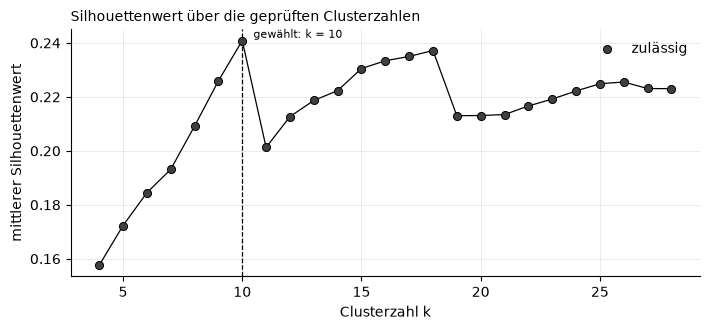

In [26]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(df_raster["k"], df_raster["silhouette"], color="black", linewidth=0.9, zorder=2)
teil = df_raster[df_raster["zulaessig"]]
ax.scatter(teil["k"], teil["silhouette"], s=34, facecolor="0.25", edgecolor="black", linewidths=0.7,
           label="zulässig", zorder=3)
ax.axvline(k_gewaehlt, color="black", linestyle="--", linewidth=0.9)
ax.annotate("gewählt: k = " + str(k_gewaehlt), (k_gewaehlt, sil_gewaehlt), xytext=(8, 2),
            textcoords="offset points", fontsize=8)
ax.set_title("Silhouettenwert über die geprüften Clusterzahlen", loc="left", fontsize=10)
ax.set_xlabel("Clusterzahl k")
ax.set_ylabel("mittlerer Silhouettenwert")
ax.grid(color="0.9", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(AUSGABE / "abbildung2_silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

**Tabelle 3:** Figurencluster

In [27]:
#Leitmerkmale je Figurencluster: Keyness der Gruppe gegen die übrigen Rollen (Clusterebene);
#genannt werden bis zu vier signifikant überrepräsentierte Adjektivcluster mit dem höchsten G²
df_gruppen = df_belege[df_belege["figur"].isin(figurencluster.index)].copy()
df_gruppen["figurencluster"] = df_gruppen["figur"].map(figurencluster).astype(str)
keyness_gruppen = berechne_keyness(df_gruppen, "merkmal_cluster", gruppenspalte="figurencluster")

zeilen = []
for gruppe in sorted(set(figurencluster.values)):
    mitglieder = sorted(figurencluster[figurencluster == gruppe].index)
    leit = keyness_gruppen[(keyness_gruppen["figurencluster"] == str(gruppe)) & (keyness_gruppen["richtung"] == "über")
                           & keyness_gruppen["signifikant"]].nlargest(4, "g2")
    zeilen.append({"Gruppe": str(gruppe) + " (" + str(len(mitglieder)) + " Rollen)",
                   "Rollen": ", ".join(mitglieder),
                   "Leitmerkmal (Log-Ratio)": ", ".join(z["merkmal_cluster"] + " (" + format(z["log_ratio"], "+.1f") + ")"
                                                        for _, z in leit.iterrows())})
tabelle3 = pd.DataFrame(zeilen)
tabelle3

,Gruppe,Rollen,Leitmerkmal (Log-Ratio)
0,1 (11 Rollen),"Baum, Gerda, Hund, Ida, Kay, Kerl, Knabe, Mädchen, Räubermädchen, Sperling, Vogel",KLEIN (+3.9)
1,2 (20 Rollen),"Alte, Bruder, Fischer, Frau, Freund, Gesell, Großmutter, Herr, Hexe, Junge, König, Königin, Mann, Mustapha, Mutter, Prinz, Schneider, Sohn, Vater, Weib","ALTE/JUNG/BETAGT (+3.4), LIEB/GLÜCKLICH/EINSAM (+1.0), KRANK/GESUND/GIFTIG (+1.6)"
2,3 (11 Rollen),"Ali Baba, Arzt, Chodadad, Hans, Hase, Landmann, Perser, Räuber, Sklavin Morgiana, Steinhauer, Urashima","STILL/LEISE/RUHIG (+2.3), GESCHICKT/BELADEN/UNGESCHICKT (+4.2), SCHNELL (+2.2), FROH/ERFREUT/STOLZ (+2.0)"
3,4 (4 Rollen),"Jäger, Schneiderlein, Schwan, Tier","WILD/GESCHWIND/MUNTER (+4.5), STARK (+3.1)"
4,5 (2 Rollen),"Diener, Johannes",TREU (+7.8)
5,6 (10 Rollen),"Apfel, Bruder Lustig, Casim, Dachs, Frosch, Gott, Kaiser, Petrus, Sultan, Ziege","HEILIG/GOTTLOS/FROMM (+4.1), LUSTIG/TRAURIG/GARSTIG (+3.5), ALLMÄCHTIG/ERHABEN/WÜRDIG (+4.5), MÜDE/SATT/HUNGRIG (+2.3)"
6,7 (8 Rollen),"Blume, Fee, Fisch, Jüngling, Königstochter, Prinzessin, Rose, Sklave","BUNT/GOLDEN/BLÜHEND (+7.1), BUNT (+3.3), SCHÖN/HÜBSCH/FEIN (+2.0), FREUNDLICH/HERRLICH/LIEBLICH (+1.6)"
7,8 (14 Rollen),"Bär, Daumerling, Daumesdick, Däumelieschen, Elise, Gans, Geist, Kind, Kleine, Schwesterchen, Soldat, Teufel, Tochter, Zauberin","ARM/BÖS/DUMM (+1.9), ABGEDANKT/EINSTIMMIG/VERABSCHIEDET (+4.6), HÄSSLICH/SCHLECHT/BITTERLICH (+1.6), UNSCHULDIG/SCHULDIG/LEDIG (+2.1)"
8,9 (3 Rollen),"Braut, Nachtigall, Tod",WIRKLICH (+4.7)
9,10 (3 Rollen),"Bauer, Kaufmann, Leute","REICH/PRÄCHTIG/STATTLICH (+4.2), SELTSAM (+3.9), HEFTIG (+3.0), TAPFER (+3.6)"


Fehlerkennung Apfel.

In [28]:
#Normformen der Rolle Apfel (Fehlerkennung in Gruppe 6)
apfel = df_belege[df_belege["figur"] == "Apfel"]
print("Apfel: Gruppe", figurencluster["Apfel"], "|", len(apfel), "Belege |",
      ", ".join(n + " (" + str(k) + ")" for n, k in apfel["merkmal_normform"].value_counts().items()))

Apfel: Gruppe 6 | 13 Belege | künstlich (9), giftig (2), fertig (1), schön (1)


Abhängigkeit von der Parameterwahl (bereinigter Rand-Index).

In [29]:
def ari_gegen_variante(ebene, min_belege):
    """Bereinigter Rand-Index (Hubert und Arabie 1985) gegen eine Variante, auf den gemeinsamen Rollen."""
    M2 = baue_vektoren(df_belege, ebene, min_belege)
    l2, _, _, _ = waehle_zerlegung(M2)
    v2 = pd.Series(l2, index=M2.index)
    gemeinsam = figurencluster.index.intersection(v2.index)
    return adjusted_rand_score(figurencluster[gemeinsam], v2[gemeinsam]), len(gemeinsam)


ari, n = ari_gegen_variante("merkmal_cluster", MIN_BELEGE_VEKTOR_SENSITIV)
print("Mindestbelege 5 statt 10: ARI", format(ari, ".3f"), "auf", n, "Rollen")
ari, n = ari_gegen_variante("merkmal_normform", MIN_BELEGE_VEKTOR)
print("Normformen statt Cluster: ARI", format(ari, ".3f"), "auf", n, "Rollen")

Mindestbelege 5 statt 10: ARI 0.417 auf 86 Rollen
Normformen statt Cluster: ARI 0.335 auf 86 Rollen


### 7.2.4 Rollenpaare und Genderachse

Rollenpaare.

In [30]:
#Paarvergleich auf der Clusterebene: Referenz ist die Partnerrolle, nicht der Korpusrest
for figur_a, figur_b in PAARE:
    teil = df_belege[df_belege["figur"].isin([figur_a, figur_b])].dropna(subset=["merkmal_cluster"])
    groessen = teil.groupby("figur").size()
    if any(groessen.get(f, 0) < MIN_BELEGE_PROFIL for f in (figur_a, figur_b)):
        print(figur_a, "/", figur_b + ": weniger als", MIN_BELEGE_PROFIL, "Belege")
        continue
    kt = berechne_keyness(teil, "merkmal_cluster")
    for figur in (figur_a, figur_b):
        print(figur + ":", int(groessen[figur]), "Belege aus", teil.loc[teil["figur"] == figur, "maerchen"].nunique(), "Märchen")
        for _, z in kt[(kt["figur"] == figur) & (kt["richtung"] == "über")].nlargest(6, "g2").iterrows():
            print("   ", z["merkmal_cluster"], "|", int(z["belege"]), "Belege | Log-Ratio", round(float(z["log_ratio"]), 1),
                  "| signifikant" if z["signifikant"] else "")
    print()

König: 101 Belege aus 19 Märchen
    KRANK/GESUND/GIFTIG | 9 Belege | Log-Ratio 2.4 
    ZORNIG/EILIG/GRIMMIG | 8 Belege | Log-Ratio 2.2 
    GUT/GENAU/FALSCH | 5 Belege | Log-Ratio 1.6 
    FREUNDLICH/HERRLICH/LIEBLICH | 4 Belege | Log-Ratio 1.3 
    STILL/LEISE/RUHIG | 4 Belege | Log-Ratio 1.3 
    KLEIN | 3 Belege | Log-Ratio 1.0 
Königin: 28 Belege aus 8 Märchen
    ARM/BÖS/DUMM | 4 Belege | Log-Ratio 5.0 | signifikant
    BUNT | 3 Belege | Log-Ratio 4.7 | signifikant
    SCHÖN/HÜBSCH/FEIN | 3 Belege | Log-Ratio 3.1 

Prinz: 79 Belege aus 6 Märchen
    LIEB/GLÜCKLICH/EINSAM | 8 Belege | Log-Ratio 2.7 
    LANG/ENTFERNT/NAHE | 6 Belege | Log-Ratio 2.3 
    PLÖTZLICH/HEIMLICH/SCHLICH | 5 Belege | Log-Ratio 2.1 
    BEKANNT | 4 Belege | Log-Ratio 1.8 
    FRISCH/DICHT/BEDECKT | 4 Belege | Log-Ratio 1.8 
    GUT/GENAU/FALSCH | 3 Belege | Log-Ratio 1.4 
Prinzessin: 30 Belege aus 7 Märchen
    SCHÖN/HÜBSCH/FEIN | 5 Belege | Log-Ratio 2.5 
    FREUNDLICH/HERRLICH/LIEBLICH | 3 Belege | Log

Geschlecht der Rollen aus den Pronomen der Koreferenzprotokolle. Die vollständige Zuordnung wird für den Anhang gespeichert.

In [31]:
def norm_text(s):
    #Vergleichsform: NFC, getrimmt, klein
    return unicodedata.normalize("NFC", str(s)).strip().lower()


#Oberflächenform -> eindeutiger Anzeigename der Rolle (aus der Schlüsselkarte des Exports)
form_zu_namen = defaultdict(set)
for schluessel, eintrag in daten["figuren_schluessel_karte"].items():
    name = eintrag.get("anzeigename") or schluessel
    for form in list(eintrag.get("formen", {})) + [schluessel, name]:
        form_zu_namen[norm_text(form)].add(name)
form_zu_name = {f: next(iter(n)) for f, n in form_zu_namen.items() if len(n) == 1}


def cluster_iter(objekt):
    """Alle Koreferenzcluster eines Fensterprotokolls einsammeln."""
    if isinstance(objekt, dict):
        if isinstance(objekt.get("cluster"), list):
            yield from objekt["cluster"]
        for wert in objekt.values():
            yield from cluster_iter(wert)
    elif isinstance(objekt, list):
        for element in objekt:
            yield from cluster_iter(element)


#Pronomen je Rolle: Ein Cluster zählt, wenn mindestens 80 Prozent seiner Pronomen in dieselbe
#Richtung weisen; gutgeschrieben wird allen tragend genannten Rollen des Clusters
pron_je_rolle = defaultdict(Counter)
gelesen = 0
for eintrag in korpus_meta["maerchen"]:
    datei = eintrag.get("coref_protokoll_datei")
    if not datei or not (P_PROTOKOLLE / datei).exists():
        continue
    protokoll = json.loads((P_PROTOKOLLE / datei).read_text(encoding="utf-8"))
    gelesen += 1
    for cluster in cluster_iter(protokoll):
        if not isinstance(cluster, dict):
            continue
        worte = [norm_text(m.get("text") if isinstance(m, dict) else m).strip(".,;:!?»«\"'")
                 for m in cluster.get("mentions", [])]
        rep = cluster.get("repraesentant")
        name_rep = form_zu_name.get(norm_text(rep)) if rep else None
        nennungen = Counter(form_zu_name[w] for w in worte if w in form_zu_name)
        if name_rep:
            nennungen[name_rep] += 1
        rollen_im_cluster = {name for name, anzahl in nennungen.items()
                             if anzahl >= GENUS_MIN_ERWAEHNUNGEN or name == name_rep or len(nennungen) == 1}
        maskulin = sum(1 for w in worte if w in PRONOMEN_MASKULIN)
        feminin = sum(1 for w in worte if w in PRONOMEN_FEMININ)
        if not rollen_im_cluster or maskulin + feminin == 0:
            continue
        if max(maskulin, feminin) / (maskulin + feminin) < GENUS_CLUSTER_EINHEIT:
            continue
        for name in rollen_im_cluster:
            pron_je_rolle[name]["maskulin"] += maskulin
            pron_je_rolle[name]["feminin"] += feminin
print("Gelesene Koreferenzprotokolle:", gelesen)

#Plural- und Kollektivanteil je Rolle: "sie" bezeichnet auch die Mehrzahl
numerus_rolle = (df_belege.assign(plural=df_belege["numerus"].eq("Plur")).groupby("figur")
                 .agg(plural_anteil=("plural", "mean"), kollektiv_anteil=("kollektiv", "mean")))


def klassifiziere_genus(rolle):
    """maskulin, feminin, unbestimmt oder ausgeschlossen."""
    if (numerus_rolle["plural_anteil"].get(rolle, 0.0) > GENUS_MAX_PLURALANTEIL
            or numerus_rolle["kollektiv_anteil"].get(rolle, 0.0) > 0.5):
        return "ausgeschlossen"
    m = pron_je_rolle[rolle]["maskulin"]
    f = pron_je_rolle[rolle]["feminin"]
    if m + f < GENUS_MIN_PRONOMEN:
        return "unbestimmt"
    if m / (m + f) >= GENUS_DOMINANZ:
        return "maskulin"
    if f / (m + f) >= GENUS_DOMINANZ:
        return "feminin"
    return "unbestimmt"


belegzahl = df_belege.groupby("figur").size()
df_genus = pd.DataFrame([{"figur": rolle, "genus": klassifiziere_genus(rolle),
                          "pron_maskulin": pron_je_rolle[rolle]["maskulin"],
                          "pron_feminin": pron_je_rolle[rolle]["feminin"], "belege": int(belegzahl[rolle])}
                         for rolle in sorted(belegzahl[belegzahl >= MIN_BELEGE_PROFIL].index)])
klassen = df_genus["genus"].value_counts()
print("Rollen ab", MIN_BELEGE_PROFIL, "Belegen:", len(df_genus))
for klasse in ("maskulin", "feminin", "unbestimmt", "ausgeschlossen"):
    print("  ", klasse + ":", int(klassen.get(klasse, 0)))
df_genus.to_csv(AUSGABE / "geschlecht_der_rollen.csv", index=False, encoding="utf-8")
print("Gespeichert:", AUSGABE / "geschlecht_der_rollen.csv")

Gelesene Koreferenzprotokolle: 80
Rollen ab 5 Belegen: 164
   maskulin: 71
   feminin: 34
   unbestimmt: 43
   ausgeschlossen: 16
Gespeichert: ergebnisse_kapitel7/geschlecht_der_rollen.csv


**Tabelle 4:** Merkmale (Gender/Rolle)

In [32]:
#Belege der weiblichen gegen die der männlichen Rollen
genus_von = dict(zip(df_genus["figur"], df_genus["genus"]))
df_achse = df_belege.assign(genus=df_belege["figur"].map(genus_von))
df_achse = df_achse[df_achse["genus"].isin(["feminin", "maskulin"])]
n_weiblich = int((df_achse["genus"] == "feminin").sum())
n_maennlich = int((df_achse["genus"] == "maskulin").sum())
print("Belege weiblich:", n_weiblich, "| männlich:", n_maennlich, "| Faktor:", round(n_maennlich / n_weiblich, 2),
      "| Rollen:", df_achse["figur"].nunique())


def rollendominanz(df, ebene):
    """Je Seite und Merkmal: Zahl der Rollen und die Rolle mit den meisten Belegen."""
    n_rollen = df.groupby(["genus", ebene])["figur"].nunique().rename("n_rollen").reset_index()
    dominant = (df.groupby(["genus", ebene, "figur"]).size().rename("n").reset_index()
                .sort_values("n", ascending=False).drop_duplicates(["genus", ebene])
                .rename(columns={"figur": "dominante_rolle", "n": "rolle_belege"}))
    return n_rollen.merge(dominant, on=["genus", ebene])


keyness_achse = {}
for spalte in MERKMALSEBENEN:
    kt = berechne_keyness(df_achse, spalte, gruppenspalte="genus")
    kt = kt.merge(rollendominanz(df_achse, spalte), on=["genus", spalte])
    kt["rollendominanz"] = kt["rolle_belege"] / kt["belege"]
    keyness_achse[spalte] = kt

#Tabelle 4: signifikant überrepräsentierte Cluster je Seite, nach Log-Ratio
kt = keyness_achse["merkmal_cluster"]
zaehlung = df_achse.dropna(subset=["merkmal_cluster"]).groupby(["genus", "merkmal_cluster"]).size().to_dict()
zeilen = []
for richtung, seite, gegen in (("feminin", "weiblich", "maskulin"), ("maskulin", "männlich", "feminin")):
    auswahl = kt[(kt["genus"] == richtung) & (kt["richtung"] == "über") & kt["signifikant"]]
    for _, z in auswahl.sort_values("log_ratio", ascending=False).iterrows():
        eigen, partner = int(z["belege"]), int(zaehlung.get((gegen, z["merkmal_cluster"]), 0))
        weiblich, maennlich = (eigen, partner) if richtung == "feminin" else (partner, eigen)
        zeilen.append({"Seite": seite, "Cluster": z["merkmal_cluster"],
                       "Belege weiblich : männlich": str(weiblich) + " : " + str(maennlich),
                       "Log-Ratio": round(float(z["log_ratio"]), 1), "Rollen": int(z["n_rollen"]),
                       "stärkste Rolle (Anteil)": z["dominante_rolle"] + " (" + str(round(100 * z["rollendominanz"])) + " %)"})
tabelle4 = pd.DataFrame(zeilen)
tabelle4

Belege weiblich: 1040 | männlich: 1776 | Faktor: 1.71 | Rollen: 105


,Seite,Cluster,Belege weiblich : männlich,Log-Ratio,Rollen,stärkste Rolle (Anteil)
0,weiblich,SCHÖN/HÜBSCH/FEIN,84 : 19,2.8,16,Mädchen (24 %)
1,weiblich,FREUNDLICH/HERRLICH/LIEBLICH,31 : 23,1.1,11,Mädchen (35 %)
2,weiblich,KLEIN,126 : 107,1.0,9,Mädchen (38 %)
3,männlich,ALLMÄCHTIG/ERHABEN/WÜRDIG,0 : 34,5.4,7,Gott (74 %)
4,männlich,TREU,2 : 42,3.4,6,Johannes (76 %)
5,männlich,GELEHRT/GEMACHT/GEMEIN,0 : 8,3.4,5,Herr (38 %)
6,männlich,ZORNIG/EILIG/GRIMMIG,4 : 33,2.2,19,König (24 %)
7,männlich,LUSTIG/TRAURIG/GARSTIG,11 : 85,2.2,20,Bruder Lustig (66 %)
8,männlich,REICH/PRÄCHTIG/STATTLICH,5 : 30,1.7,12,Mann (27 %)


Normform „jung“ und Genderachse innerhalb der Sammlungen.

In [33]:
#Normform "jung" auf der Genderachse
kt = keyness_achse["merkmal_normform"]
z = kt[(kt["genus"] == "maskulin") & (kt["merkmal_normform"] == "jung")].iloc[0]
weiblich = int(((df_achse["genus"] == "feminin") & (df_achse["merkmal_normform"] == "jung")).sum())
print("jung: männlich", int(z["belege"]), "| weiblich", weiblich, "| Log-Ratio", round(float(z["log_ratio"]), 1),
      "| signifikant:", bool(z["signifikant"]))

#Genderachse innerhalb der Sammlungen (Clusterebene)
zeilen = []
for sammlung, teil in df_achse.groupby("sammlung"):
    ks = berechne_keyness(teil, "merkmal_cluster", gruppenspalte="genus")
    if ks.empty:
        continue
    zeilen.append({"Sammlung": sammlung, "getestete Zellen": len(ks), "signifikant": int(ks["signifikant"].sum())})
pd.DataFrame(zeilen)

jung: männlich 63 | weiblich 17 | Log-Ratio 1.1 | signifikant: True


,Sammlung,getestete Zellen,signifikant
0,Arabische Märchen,72,5
1,Brüder Grimm,81,15
2,H. C. Andersen,40,0
3,Japanische Märchen,39,1
